In [2]:
import stim
from typing import List
from pathlib import Path

In [5]:
circuit = stim.Circuit.from_file('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/circuit_ideal.stim')
diagram = circuit.diagram(type='timeline-3d')
# display(diagram)
print(circuit)

QUBIT_COORDS(2, 4) 0
QUBIT_COORDS(2, 5) 1
QUBIT_COORDS(3, 4) 2
QUBIT_COORDS(3, 5) 3
QUBIT_COORDS(3, 6) 4
QUBIT_COORDS(3, 7) 5
QUBIT_COORDS(4, 2) 6
QUBIT_COORDS(4, 3) 7
QUBIT_COORDS(4, 4) 8
QUBIT_COORDS(4, 5) 9
QUBIT_COORDS(4, 6) 10
QUBIT_COORDS(4, 7) 11
QUBIT_COORDS(5, 2) 12
QUBIT_COORDS(5, 3) 13
QUBIT_COORDS(5, 4) 14
QUBIT_COORDS(5, 5) 15
QUBIT_COORDS(5, 6) 16
QUBIT_COORDS(5, 7) 17
QUBIT_COORDS(5, 8) 18
QUBIT_COORDS(5, 9) 19
QUBIT_COORDS(6, 1) 20
QUBIT_COORDS(6, 2) 21
QUBIT_COORDS(6, 3) 22
QUBIT_COORDS(6, 4) 23
QUBIT_COORDS(6, 5) 24
QUBIT_COORDS(6, 6) 25
QUBIT_COORDS(6, 7) 26
QUBIT_COORDS(6, 8) 27
QUBIT_COORDS(6, 9) 28
QUBIT_COORDS(7, 1) 29
QUBIT_COORDS(7, 2) 30
QUBIT_COORDS(7, 3) 31
QUBIT_COORDS(7, 4) 32
QUBIT_COORDS(7, 5) 33
QUBIT_COORDS(7, 6) 34
QUBIT_COORDS(7, 7) 35
QUBIT_COORDS(7, 8) 36
QUBIT_COORDS(8, 3) 37
QUBIT_COORDS(8, 4) 38
QUBIT_COORDS(8, 5) 39
QUBIT_COORDS(8, 6) 40
QUBIT_COORDS(8, 7) 41
QUBIT_COORDS(8, 8) 42
QUBIT_COORDS(9, 3) 43
QUBIT_COORDS(9, 4) 44
QUBIT_COORDS(9, 5) 4

In [10]:
# circuit.diagram('detslice-text')

In [11]:
print(f'Qubits: {circuit.num_qubits}')
print(f'Detectors: {circuit.num_detectors}')
print(f'Observables: {circuit.num_observables}')

Qubits: 49
Detectors: 648
Observables: 1


#### The b8 format

In [12]:
def parse_b8(data: bytes, bits_per_shot: int) -> List[List[bool]]:
    shots = []
    bytes_per_shot = (bits_per_shot + 7) // 8
    for offset in range(0, len(data), bytes_per_shot):
        shot = []
        for k in range(bits_per_shot):
            byte = data[offset + k // 8]
            bit = (byte >> (k % 8)) % 2 == 1
            shot.append(bit)
        shots.append(shot)
    return shots

##### Detection events

In [13]:
num_detectors = circuit.num_detectors
raw_detection_events_data_path = Path('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/detection_events.b8')
raw_detection_events_data = raw_detection_events_data_path.read_bytes()
shots = parse_b8(raw_detection_events_data, num_detectors)

print(f'Bits in parsed shot: {len(shots[0])}')
print(f'Number of shots: {len(shots)}')

Bits in parsed shot: 648
Number of shots: 75000


##### Measurements

In [14]:
num_measurements = circuit.num_measurements
raw_measurements_data_path = Path('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/measurements.b8')
raw_measurements_data = raw_measurements_data_path.read_bytes()
measurements = parse_b8(raw_measurements_data, num_measurements)

print(f'Bits in parsed measurement: {len(measurements[0])}')

Bits in parsed measurement: 673


##### Sweep bits

In [15]:
num_sweep_bits = circuit.num_sweep_bits
raw_sweep_bits_data_path = Path('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/sweep_bits.b8')
raw_sweep_bits_data = raw_sweep_bits_data_path.read_bytes()
sweep_bits = parse_b8(raw_sweep_bits_data, num_sweep_bits)

print(f'Bits in parsed sweep bit: {len(sweep_bits[0])}')

Bits in parsed sweep bit: 25


##### Observable flip data

In [16]:
num_observables = 1 # specific to the dataset
raw_obs_flips_actual_data_path = Path('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/obs_flips_actual.b8')
raw_obs_flips_actual_data = raw_obs_flips_actual_data_path.read_bytes()
obs_flips = parse_b8(raw_obs_flips_actual_data, num_observables)

print(f'Bits in parsed observable flip: {len(obs_flips[0])}')

Bits in parsed observable flip: 1


#### Detector coordinates

In [17]:
import json

with open('/Users/andreidolmatov/Desktop/Studies/6th Semester/Thesis/thesis_vscode/data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/metadata.json', 'r') as f:
    metadata = f.read()
    parsed_metadata = json.loads(metadata)
    q_coords = parsed_metadata['data_qubit_coords']
    m_coords = parsed_metadata['meas_qubit_coords']

q_xs, q_ys = zip(*q_coords)
m_xs, m_ys = zip(*m_coords)

print(f'data qubit coordinates: \n \t x: {q_xs} \n \t y: {q_ys}')
print(f'measurement qubit coordinates: \n \t x: {m_xs} \n \t y: {m_ys}')

FileNotFoundError: [Errno 2] No such file or directory: '/Users/andreidolmatov/Desktop/Studies/6th Semester/Thesis/thesis_vscode/data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/metadata.json'

In [ ]:
# m_xs, m_ys = zip(*m_coords)
# m_xs = [x - 1 for x in m_xs]
# m_ys = [y - 1 for y in m_ys]

# q_xs, q_ys = zip(*q_coords)
# q_xs = [x - 1 for x in q_xs]
# q_ys = [y - 1 for y in q_ys]

# print(f'data qubit coordinates: \n \t{q_xs} \n \t{q_ys}')
# print(f'measurement qubit coordinates: \n \t{m_xs} \n \t{m_ys}')

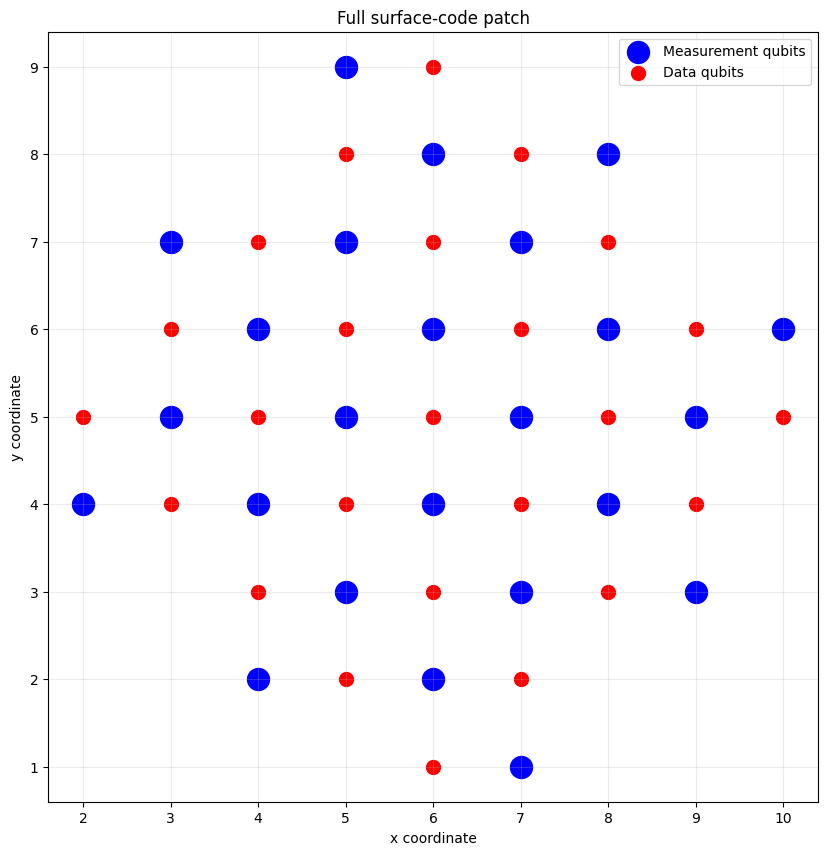

In [ ]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(figsize=(10, 10))

axis.scatter(
    m_xs,
    m_ys,
    color='blue',
    label='Measurement qubits',
    s=250
)

axis.scatter(
    q_xs,
    q_ys,
    color='red',
    label='Data qubits',
    s=100
)

axis.set_xlabel('x coordinate')
axis.set_ylabel('y coordinate')
axis.set_title('Full surface-code patch')
axis.set_aspect('equal')
axis.grid(alpha=0.25)
axis.legend()

plt.show()

In [ ]:
from collections import defaultdict

def xy(coordinates):
    return tuple(float(value) for value in coordinates[:2])

qubit_coordinates = {qubit: xy(coordinates) for qubit, coordinates in circuit.get_final_qubit_coordinates().items()}

measurement_coordinates = {(float(x), float(y)) for x, y in zip(m_xs, m_ys)}
data_coordinates = {(float(x), float(y)) for x, y in zip(q_xs, q_ys)}

measurement_qubits = {qubit for qubit, coordinate in qubit_coordinates.items() if coordinate in measurement_coordinates}

data_qubits = {qubit for qubit, coordinate in qubit_coordinates.items() if coordinate in data_coordinates}

print(f'Measurement qubits: {sorted(measurement_qubits)}')
print(f'Data qubits: {sorted(data_qubits)}')

Measurement qubits: [0, 3, 5, 6, 8, 10, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 38, 40, 42, 43, 45, 48]
Data qubits: [1, 2, 4, 7, 9, 11, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 37, 39, 41, 44, 46, 47]


In [ ]:
stabilizer_support = defaultdict(set)

for instruction in circuit.flattened():
    gate = stim.gate_data(instruction.name)
    if not gate.is_two_qubit_gate:
        continue
    if not gate.is_unitary:
        continue
    targets = instruction.targets_copy()

    for index in range(0, len(targets), 2):
        first = targets[index]
        second = targets[index + 1]

        if not first.is_qubit_target:
            continue

        if not second.is_qubit_target:
            continue

        first_qubit = first.value
        second_qubit = second.value

        if (first_qubit in measurement_qubits and second_qubit in data_qubits):
            stabilizer_support[first_qubit].add(second_qubit)

        elif (second_qubit in measurement_qubits and first_qubit in data_qubits):
            stabilizer_support[second_qubit].add(first_qubit)

In [ ]:
for measurement_qubit in sorted(stabilizer_support):
    data_support = sorted(stabilizer_support[measurement_qubit])

    print(f'Measurement qubit {measurement_qubit} ' f'at {qubit_coordinates[measurement_qubit]}')

    for data_qubit in data_support:
        print(f'  -> data qubit {data_qubit} ' f'at {qubit_coordinates[data_qubit]}')

Measurement qubit 0 at (2.0, 4.0)
  -> data qubit 1 at (2.0, 5.0)
  -> data qubit 2 at (3.0, 4.0)
Measurement qubit 3 at (3.0, 5.0)
  -> data qubit 1 at (2.0, 5.0)
  -> data qubit 2 at (3.0, 4.0)
  -> data qubit 4 at (3.0, 6.0)
  -> data qubit 9 at (4.0, 5.0)
Measurement qubit 5 at (3.0, 7.0)
  -> data qubit 4 at (3.0, 6.0)
  -> data qubit 11 at (4.0, 7.0)
Measurement qubit 6 at (4.0, 2.0)
  -> data qubit 7 at (4.0, 3.0)
  -> data qubit 12 at (5.0, 2.0)
Measurement qubit 8 at (4.0, 4.0)
  -> data qubit 2 at (3.0, 4.0)
  -> data qubit 7 at (4.0, 3.0)
  -> data qubit 9 at (4.0, 5.0)
  -> data qubit 14 at (5.0, 4.0)
Measurement qubit 10 at (4.0, 6.0)
  -> data qubit 4 at (3.0, 6.0)
  -> data qubit 9 at (4.0, 5.0)
  -> data qubit 11 at (4.0, 7.0)
  -> data qubit 16 at (5.0, 6.0)
Measurement qubit 13 at (5.0, 3.0)
  -> data qubit 7 at (4.0, 3.0)
  -> data qubit 12 at (5.0, 2.0)
  -> data qubit 14 at (5.0, 4.0)
  -> data qubit 22 at (6.0, 3.0)
Measurement qubit 15 at (5.0, 5.0)
  -> data qub

#### Masking

Bounding box and mask

In [ ]:
import numpy as np

bounding_box_dims = (np.max(m_ys), np.max(m_xs))
print(bounding_box_dims)

placeholder = np.empty(bounding_box_dims)
mask_m_xs = [x - 1 for x in m_xs]
mask_m_ys = [y - 1 for y in m_ys]
placeholder[mask_m_ys, mask_m_xs] = 1
print(placeholder)

(9, 10)
[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 1. 0. 1. 0.]
 [0. 1. 0. 1. 0. 1. 0. 1. 0. 0.]
 [0. 0. 1. 0. 1. 0. 1. 0. 1. 0.]
 [0. 0. 0. 1. 0. 1. 0. 1. 0. 1.]
 [0. 0. 1. 0. 1. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]


### Overview

In [18]:
circuit = stim.Circuit.from_file('../data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/circuit_ideal.stim')

In [20]:
for instruction in circuit.flattened():
    if instruction.name in {
        'DETECTOR',
        'OBSERVABLE_INCLUDE',
        'QUBIT_COORDS',
    }:
        print(instruction)

QUBIT_COORDS(2, 4) 0
QUBIT_COORDS(2, 5) 1
QUBIT_COORDS(3, 4) 2
QUBIT_COORDS(3, 5) 3
QUBIT_COORDS(3, 6) 4
QUBIT_COORDS(3, 7) 5
QUBIT_COORDS(4, 2) 6
QUBIT_COORDS(4, 3) 7
QUBIT_COORDS(4, 4) 8
QUBIT_COORDS(4, 5) 9
QUBIT_COORDS(4, 6) 10
QUBIT_COORDS(4, 7) 11
QUBIT_COORDS(5, 2) 12
QUBIT_COORDS(5, 3) 13
QUBIT_COORDS(5, 4) 14
QUBIT_COORDS(5, 5) 15
QUBIT_COORDS(5, 6) 16
QUBIT_COORDS(5, 7) 17
QUBIT_COORDS(5, 8) 18
QUBIT_COORDS(5, 9) 19
QUBIT_COORDS(6, 1) 20
QUBIT_COORDS(6, 2) 21
QUBIT_COORDS(6, 3) 22
QUBIT_COORDS(6, 4) 23
QUBIT_COORDS(6, 5) 24
QUBIT_COORDS(6, 6) 25
QUBIT_COORDS(6, 7) 26
QUBIT_COORDS(6, 8) 27
QUBIT_COORDS(6, 9) 28
QUBIT_COORDS(7, 1) 29
QUBIT_COORDS(7, 2) 30
QUBIT_COORDS(7, 3) 31
QUBIT_COORDS(7, 4) 32
QUBIT_COORDS(7, 5) 33
QUBIT_COORDS(7, 6) 34
QUBIT_COORDS(7, 7) 35
QUBIT_COORDS(7, 8) 36
QUBIT_COORDS(8, 3) 37
QUBIT_COORDS(8, 4) 38
QUBIT_COORDS(8, 5) 39
QUBIT_COORDS(8, 6) 40
QUBIT_COORDS(8, 7) 41
QUBIT_COORDS(8, 8) 42
QUBIT_COORDS(9, 3) 43
QUBIT_COORDS(9, 4) 44
QUBIT_COORDS(9, 5) 4

In [12]:
dem_path = '/Users/andreidolmatov/Desktop/Thesis/quant/data/sycamore_surface_code_d3_d5/sample_00/d5_at_q6_5/X/r25/dems/correlations.dem'
dem = stim.DetectorErrorModel.from_file(str(dem_path))

In [13]:
print(dem)

error(0.00516033729641059) D0 D2
error(0.004254743297433446) D0 D3
error(0.002395980544620354) D0 D3 ^ D16
error(0.01116437653792179) D0 D12
error(0.002256979331510911) D0 D12 ^ D16
error(0.004875614177303132) D0 D15
error(0.002603092123909309) D0 D15 ^ D16
error(0.002079840142341497) D0 D17
error(0.001103196208466) D0 D17 ^ D16
error(0.001988248012650152) D0 D20
error(0.0009562295739769919) D0 D20 ^ D16
error(0.01) D1
error(0.004846018878964059) D1 D3
error(0.02037752596563429) D1 D13
error(0.004289008021804422) D1 D13 ^ D18
error(0.004600977847843527) D1 D17
error(0.002134315523541883) D1 D17 ^ D18
error(0.001969252532491294) D1 D22
error(0.002519845373691475) D1 D22 ^ D18
error(0.009560000674452765) D1 ^ D18
error(0.005002059460431221) D2 D4
error(0.003253944283778715) D2 D4 ^ D19
error(0.01911329881613848) D2 D15
error(0.0007719859272264565) D2 D15 ^ D14
error(0.0008020698724082657) D2 D15 ^ D14 D19
error(0.0004254111338341689) D2 D15 ^ D19
error(0.002227266878051002) D2 D20
error(